# 05 — Comparação mundial: correlação comum e meta-análise (spec 004)

**Pergunta:** como a associação entre uso de tela e sono no Brasil se posiciona frente a outros países e à literatura?

As bases usam escalas diferentes (índice de insônia, PSQI, AIS, latência em minutos), então a razão de prevalências da spec 003 não serve para todas. A métrica comum é a **correlação de Spearman (ρ)** entre exposição e desfecho, com sinal padronizado: **positivo = mais tela, pior sono**. As correlações das 7 bases são combinadas por **meta-análise de efeitos aleatórios (DerSimonian e Laird, 1986)**.

Os pares exposição × desfecho, a família de testes (H4.1–H4.4, com Holm) e as regras de decisão foram fixados no plano antes do cálculo (`specs/004-comparacao-mundial/plan.md`).

In [1]:
import sys, os
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd
from scipy import stats
from IPython.display import Image, display
from statsmodels.stats.meta_analysis import combine_effects
from analise.comum import caminhos
from analise.comum.estatistica import le_csv, holm, formata_p
from analise.mundial import metodos as M, rodar
from analise.mundial.pares import PRINCIPAIS
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
TAB = caminhos.RESULTADOS / "004" / "tabelas"; FIG = caminhos.RESULTADOS / "004" / "figuras"
pd.DataFrame([dict(base=p.base, tipo=p.tipo, exposicao=p.rot_exposicao, desfecho=p.rot_desfecho, inverte=p.inverte)
              for p in PRINCIPAIS])

,base,tipo,exposicao,desfecho,inverte
0,pns2019,tempo total,computador/tablet/celular no lazer (6 faixas),problema no sono nas últimas 2 semanas (0-3),False
1,vigitel2024,tempo total,computador/tablet/celular no tempo livre (8 faixas),"índice de insônia, 3 sintomas (0-12)",False
2,nhanes0506,tempo total,computador/games fora do trabalho (7 faixas),"índice de insônia, 3 sintomas (0-12)",False
3,argentina,tempo total,horas de tela por dia,latência do sono (min),False
4,japao,pré-sono,horas de celular nas 3 h antes de dormir,Escala de Insônia de Atenas (8-32),False
5,xuzhou,uso problemático,"SAS-SV, dependência de smartphone (10-60)",PSQI (0-21),False
6,turquia,uso problemático,escala de doomscrolling (15-105),PSQI turco (0-21),False


## 1. Rodar a análise completa

`rodar.main()` calcula os efeitos por base (com bootstrap), a meta-análise, os testes, as sensibilidades e as figuras, e grava tudo em `resultados/004/`. As seções seguintes refazem cada passo à mão para mostrar a técnica.

In [2]:
ef, meta, hip, sens = rodar.main()

T061/T062: efeitos por base e bootstrap


  pns2019: n=88531 rho=-0.031 ep_fhp=0.00346 ep_boot=0.00332


  vigitel2024: n=27029 rho=0.063 ep_fhp=0.00626 ep_boot=0.00604


  nhanes0506: n=5551 rho=0.034 ep_fhp=0.01382 ep_boot=0.01348


  argentina: n=733 rho=0.021 ep_fhp=0.03811 ep_boot=0.03709


  japao: n=381 rho=0.145 ep_fhp=0.05296 ep_boot=0.05584


  xuzhou: n=2317 rho=0.279 ep_fhp=0.02140 ep_boot=0.02227


  turquia: n=1216 rho=0.070 ep_fhp=0.02956 ep_boot=0.03045
  regra T061: divergência máxima 5.4% -> EP usado: Fieller-Hartley-Pearson


hipotese  estatistica  gl   p_txt p_holm_txt        decisao
    H4.1   382.194307 6.0 < 0,001    < 0,001     rejeita H0
    H4.2     5.266733 2.0   0,072      0,216 não rejeita H0
    H4.3    -0.328358 NaN   0,743      1,000 não rejeita H0
    H4.4    -5.980697 NaN   1,000      1,000 não rejeita H0
                                        analise  k    rho  rho_ic_inf  rho_ic_sup        Q    p_Q     I2   tau2
                               global (7 bases)  7 0.0815      0.0167      0.1456 382.1943 0.0000 0.9843 0.0070
                          subgrupo: tempo total  4 0.0216     -0.0412      0.0842 184.5858 0.0000 0.9837 0.0038
                             subgrupo: pré-sono  1 0.1445      0.0417      0.2443   0.0000    NaN 0.0000 0.0000
                     subgrupo: uso problemático  2 0.1775     -0.0320      0.3721  34.9500 0.0000 0.9714 0.0226
                         Brasil (PNS + Vigitel)  2 0.0161     -0.0765      0.1084 174.9686 0.0000 0.9943 0.0045
outros países, tempo total (

## 2. Uma correlação passo a passo (Vigitel 2024)

1. ρ de Spearman = correlação de Pearson entre os **postos** de x e de y (empates recebem o posto médio).
2. Transformação z de Fisher: z = atanh(ρ). Na escala z a distribuição é aproximadamente normal.
3. Erro padrão de z para Spearman (Fieller, Hartley e Pearson, 1957): EP ≈ √(1,06 / (n − 3)). Para Pearson seria √(1 / (n − 3)).
4. IC 95%: z ± 1,96·EP, e volta para ρ com tanh().

In [3]:
v = pd.read_parquet(caminhos.processado("vigitel2024"))[["tela_digital_ord", "insonia_idx"]].dropna()
rx, ry = stats.rankdata(v.tela_digital_ord), stats.rankdata(v.insonia_idx)
rho = np.corrcoef(rx, ry)[0, 1]
n = len(v); z = np.arctanh(rho); ep = np.sqrt(1.06 / (n - 3))
print(f"n = {n}; ρ (postos) = {rho:.4f}; scipy = {stats.spearmanr(v.tela_digital_ord, v.insonia_idx).statistic:.4f}")
print(f"z = {z:.4f}; EP = {ep:.5f}; IC 95% de ρ = [{np.tanh(z - 1.96*ep):.4f}; {np.tanh(z + 1.96*ep):.4f}]")

n = 27029; ρ (postos) = 0.0635; scipy = 0.0635
z = 0.0636; EP = 0.00626; IC 95% de ρ = [0.0512; 0.0757]


### Conferência do erro padrão (T061)

A fórmula de Fieller, Hartley e Pearson foi derivada para dados contínuos sem empates; aqui a exposição tem poucas faixas. A regra fixada no plano: se o EP por **bootstrap** (1.000 reamostragens, semente 2026) divergir mais de 10% da fórmula em alguma base, usa-se o bootstrap em todas.

In [4]:
ef[["nome", "n", "rho", "r_pearson", "ep_fhp", "ep_bootstrap", "divergencia_rel", "ep_usado"]].round(4)

,nome,n,rho,r_pearson,ep_fhp,ep_bootstrap,divergencia_rel,ep_usado
0,PNS 2019 (Brasil),88531,-0.0311,-0.0287,0.0035,0.0033,-0.0400,Fieller-Hartley-Pearson
1,Vigitel 2024 (Brasil),27029,0.0635,0.0540,0.0063,0.0060,-0.0360,Fieller-Hartley-Pearson
2,NHANES 2005-06 (EUA),5551,0.0337,0.0314,0.0138,0.0135,-0.0245,Fieller-Hartley-Pearson
3,Pérez-Chada (Argentina),733,0.0207,0.0236,0.0381,0.0371,-0.0266,Fieller-Hartley-Pearson
4,Okajima (Japão),381,0.1445,0.1233,0.0530,0.0558,0.0545,Fieller-Hartley-Pearson
5,Xuzhou (China),2317,0.2788,0.2594,0.0214,0.0223,0.0407,Fieller-Hartley-Pearson
6,Doomscrolling (Turquia),1216,0.0705,0.0801,0.0296,0.0305,0.0302,Fieller-Hartley-Pearson


## 3. Meta-análise de efeitos aleatórios, à mão (DerSimonian e Laird)

Com efeitos yᵢ = zᵢ e variâncias vᵢ = EPᵢ²:

| Passo | Fórmula |
|---|---|
| pesos de efeito fixo | wᵢ = 1 / vᵢ |
| média de efeito fixo | μ_F = Σ wᵢ yᵢ / Σ wᵢ |
| heterogeneidade | Q = Σ wᵢ (yᵢ − μ_F)², gl = k − 1 |
| variância entre estudos | τ² = max(0, (Q − gl) / C), C = Σ wᵢ − Σ wᵢ² / Σ wᵢ |
| pesos aleatórios | wᵢ* = 1 / (vᵢ + τ²) |
| média aleatória e EP | μ = Σ wᵢ* yᵢ / Σ wᵢ*, EP = √(1 / Σ wᵢ*) |
| I² (Higgins e Thompson, 2002) | I² = max(0, (Q − gl) / Q) |

In [5]:
y, vv = ef.z.to_numpy(), (ef.ep ** 2).to_numpy()
w = 1 / vv; muF = (w * y).sum() / w.sum()
Q = (w * (y - muF) ** 2).sum(); gl = len(y) - 1
C = w.sum() - (w ** 2).sum() / w.sum(); tau2 = max(0, (Q - gl) / C)
ws = 1 / (vv + tau2); mu = (ws * y).sum() / ws.sum(); epm = np.sqrt(1 / ws.sum())
I2 = max(0, (Q - gl) / Q)
print(f"μ_F = {muF:.5f} (ρ = {np.tanh(muF):.4f});  Q = {Q:.2f}, gl = {gl}, p = {stats.chi2.sf(Q, gl):.2e}")
print(f"τ² = {tau2:.5f};  μ = {mu:.5f} -> ρ = {np.tanh(mu):.4f}, IC [{np.tanh(mu-1.96*epm):.4f}; {np.tanh(mu+1.96*epm):.4f}];  I² = {I2:.1%}")
sm = combine_effects(y, vv, method_re="dl", row_names=list(ef.nome))
print(f"statsmodels: μ = {sm.mean_effect_re:.5f}, τ² = {sm.tau2:.5f}, Q = {sm.q:.2f}, I² = {sm.i2:.1%}")
pd.DataFrame({"base": ef.nome, "peso fixo %": 100 * w / w.sum(), "peso aleatório %": 100 * ws / ws.sum()}).round(1)

μ_F = -0.00024 (ρ = -0.0002);  Q = 382.19, gl = 6, p = 1.88e-79
τ² = 0.00696;  μ = 0.08168 -> ρ = 0.0815, IC [0.0167; 0.1456];  I² = 98.4%
statsmodels: μ = 0.08168, τ² = 0.00696, Q = 382.19, I² = 98.4%


,base,peso fixo %,peso aleatório %
0,PNS 2019 (Brasil),70.4,15.8
1,Vigitel 2024 (Brasil),21.5,15.7
2,NHANES 2005-06 (EUA),4.4,15.4
3,Pérez-Chada (Argentina),0.6,13.1
4,Okajima (Japão),0.3,11.3
5,Xuzhou (China),1.8,14.8
6,Doomscrolling (Turquia),1.0,14.0


**Leitura:** com τ² > 0 os pesos aleatórios ficam quase iguais entre as bases. No efeito fixo, a PNS (n = 88 mil, ρ negativo) domina a média; no aleatório, cada base pesa entre 11% e 16%. Por isso as duas médias divergem, e a escolha do modelo aleatório (fixada no plano) importa.

In [6]:
le_csv(TAB / "conferencia_statsmodels.csv")

,quantidade,manual,statsmodels,diferenca_abs
0,média aleatória (z),0.081676,0.081676,1.387779e-17
1,EP aleatório,0.033152,0.033152,6.938894e-18
2,média fixa (z),-0.000237,-0.000237,2.466560e-18
3,Q,382.194307,382.194307,5.684342e-14
4,tau2,0.006960,0.006960,8.673617e-19
5,I2,0.984301,0.984301,0.000000e+00
6,EP Hartung-Knapp,0.039953,0.039953,0.000000e+00


### IC de Hartung-Knapp (acrescentado na verificação independente)

Com poucas bases (k = 7), o IC normal do DerSimonian-Laird é estreito demais. O método de Hartung e Knapp (2001) reescala a variância pela dispersão observada e usa t com k − 1 gl:

q = Σ wᵢ*(yᵢ − μ)² / (k − 1);  EP_HK = √(q / Σ wᵢ*);  IC = μ ± t(0,975; k − 1)·EP_HK.

Os dois intervalos aparecem lado a lado. Os testes H4.1–H4.4 não usam esse IC, então nenhuma decisão muda.

In [7]:
hk = M.hartung_knapp(y, vv, tau2); tc = stats.t.ppf(0.975, len(y) - 1)
print(f"EP_HK = {hk['ep_hk']:.5f} (statsmodels {sm.sd_eff_w_re_hksj:.5f}); q = {hk['q_hk']:.2f}")
print(f"DL: ρ IC [{np.tanh(mu-1.96*epm):.3f}; {np.tanh(mu+1.96*epm):.3f}]  |  HK: ρ IC [{np.tanh(hk['ic_inf_hk']):.3f}; {np.tanh(hk['ic_sup_hk']):.3f}], p = {hk['p_hk']:.3f}")
le_csv(TAB / "meta_analise.csv")[["analise", "k", "rho", "rho_ic_inf", "rho_ic_sup", "rho_ic_inf_hk", "rho_ic_sup_hk", "p_efeito", "p_efeito_hk", "nota"]].round(3)

EP_HK = 0.03995 (statsmodels 0.03995); q = 1.45
DL: ρ IC [0.017; 0.146]  |  HK: ρ IC [-0.016; 0.178], p = 0.087


,analise,k,rho,rho_ic_inf,rho_ic_sup,rho_ic_inf_hk,rho_ic_sup_hk,p_efeito,p_efeito_hk,nota
0,global (7 bases),7,0.081,0.017,0.146,-0.016,0.178,0.014,0.087,NaN
1,subgrupo: tempo total,4,0.022,-0.041,0.084,-0.044,0.087,0.501,0.372,NaN
2,subgrupo: pré-sono,1,0.145,0.042,0.244,NaN,NaN,0.006,NaN,k = 1: sem τ² nem IC de Hartung-Knapp (uma base só)
3,subgrupo: uso problemático,2,0.178,-0.032,0.372,-0.831,0.914,0.096,0.345,NaN
4,Brasil (PNS + Vigitel),2,0.016,-0.077,0.108,-0.526,0.549,0.734,0.791,NaN
5,"outros países, tempo total (NHANES + Argentina)",2,0.032,0.007,0.058,-0.021,0.085,0.013,0.082,NaN


### Efeito do desenho nos inquéritos

Os EP das correlações de PNS, Vigitel e NHANES supõem amostra aleatória simples. Pesos desiguais aumentam a variância por um fator de pelo menos deff = 1 + CV² dos pesos (Kish). Estrato e conglomerado não entram nessa conta. A sensibilidade multiplica a variância desses três inquéritos pelo deff e refaz a meta-análise: Q e I² caem, mas continuam enormes.

In [8]:
print(ef[["nome", "deff_kish"]].dropna().round(2).to_string(index=False))
s_ = le_csv(TAB / "sensibilidade.csv")
s_[s_.grupo == "efeito do desenho (deff)"][["analise", "k", "rho", "ic_inf", "ic_sup", "Q", "I2", "tau2", "z_teste", "p"]].round(4)

                 nome  deff_kish
    PNS 2019 (Brasil)       3.21
Vigitel 2024 (Brasil)       3.74
 NHANES 2005-06 (EUA)       1.61


,analise,k,rho,ic_inf,ic_sup,Q,I2,tau2,z_teste,p
10,PNS 2019 (Brasil): EP × √deff de Kish,1,-0.0311,-0.0432,-0.0189,NaN,NaN,NaN,NaN,NaN
11,Vigitel 2024 (Brasil): EP × √deff de Kish,1,0.0635,0.0398,0.0871,NaN,NaN,NaN,NaN,NaN
12,NHANES 2005-06 (EUA): EP × √deff de Kish,1,0.0337,-0.0006,0.0679,NaN,NaN,NaN,NaN,NaN
13,global com variância × deff de Kish nos inquéritos,7,0.0824,0.0032,0.1606,242.5864,0.9753,0.0107,NaN,NaN
14,subgrupo tempo total com variância × deff de Kish,4,0.0212,-0.0368,0.0790,54.9644,0.9454,0.0031,NaN,NaN
15,"H4.3 com variância × deff de Kish (Brasil − outros, escala z)",4,0.0157,-0.1136,0.0821,NaN,NaN,NaN,-0.3163,0.7518


## 4. Testes de hipótese (família H4.1–H4.4, Holm)

- **H4.1** heterogeneidade: Q de Cochran ~ χ²(k − 1).
- **H4.2** tipo de exposição: τ² separado por subgrupo; Q entre subgrupos = Q das três médias combinadas, gl = 2.
- **H4.3** Brasil (PNS + Vigitel, efeitos aleatórios) × outros países com tempo total (NHANES + Argentina): z = (z_BR − z_outros) / √(EP_BR² + EP_outros²).
- **H4.4** equivalência com a referência (Han, Zhou e Liu, 2024: uso geral × qualidade, r = 0,28, IC 0,21–0,35) por dois testes unilaterais (TOST): H0 = estimativa de tempo total fora de [0,21; 0,35]. p = maior dos dois p unilaterais.

In [9]:
h = le_csv(TAB / "hipoteses.csv")
h[["hipotese", "h0", "teste", "estatistica", "gl", "p_txt", "p_holm_txt", "decisao", "efeito"]]

,hipotese,h0,teste,estatistica,gl,p_txt,p_holm_txt,decisao,efeito
0,H4.1,efeito comum a todas as bases,Q de Cochran,382.194307,6.0,"< 0,001","< 0,001",rejeita H0,I² = 98.4% (IC 97.8% a 98.9%); τ² = 0.0070
1,H4.2,sem diferença entre os tipos de exposição,Q entre subgrupos,5.266733,2.0,"0,072","0,216",não rejeita H0,tempo total: ρ = 0.022 (k = 4); pré-sono: ρ = 0.145 (k = 1); uso problemátic...
2,H4.3,Brasil = outros países com tempo total,z da diferença (escala z de Fisher),-0.328358,NaN,"0,743","1,000",não rejeita H0,ρ Brasil = 0.016; ρ outros = 0.032
3,H4.4,"estimativa de tempo total fora de [0,21; 0,35] (Han, Zhou e Liu, 2024)",equivalência por dois testes unilaterais (TOST),-5.980697,NaN,"1,000","1,000",não rejeita H0,"ρ tempo total = 0.022 (IC -0.041 a 0.084); diferença para r = 0,28: z = -5.2..."


**H4.2: hipótese ordenada, teste omnibus.** A spec registrou uma ordem (tempo total < pré-sono < uso problemático), mas o teste fixado no plano é o Q entre subgrupos, que não usa a ordem. Uma meta-regressão das médias de subgrupo sobre o escore 0/1/2 entra como **exploratória** (fora da família de Holm). O subgrupo pré-sono tem k = 1 (só o Japão), então ele não tem τ² próprio.

In [10]:
le_csv(TAB / "exploratorio_referencia.csv")

,analise,rho,ic_inf,ic_sup,z,p,inclinacao_z,ep_inclinacao,p_unilateral
0,"exploratório: uso problemático × Han, Zhou e Liu (2024) r = 0,33 (IC 0,28–0,38)",0.177523,-0.031996,0.372097,-1.463942,1.432098e-01,NaN,NaN,NaN
1,"complemento de H4.4: diferença tempo total × r = 0,28",0.021568,-0.041195,0.084162,-5.285011,1.256972e-07,NaN,NaN,NaN
2,"EXPLORATÓRIO: tendência ordenada de H4.2 (escore 0 tempo total, 1 pré-sono, ...",NaN,NaN,NaN,2.219619,2.644463e-02,0.098946,0.044578,0.013222


In [11]:
print("Holm conferido:", np.allclose(holm(h.p), h.p_holm))
le_csv(TAB / "meta_analise.csv")[["analise", "k", "rho", "rho_ic_inf", "rho_ic_sup", "Q", "gl_Q", "p_Q", "tau2", "I2"]].round(4)

Holm conferido: True


,analise,k,rho,rho_ic_inf,rho_ic_sup,Q,gl_Q,p_Q,tau2,I2
0,global (7 bases),7,0.0815,0.0167,0.1456,382.1943,6,0.0000,0.0070,0.9843
1,subgrupo: tempo total,4,0.0216,-0.0412,0.0842,184.5858,3,0.0000,0.0038,0.9837
2,subgrupo: pré-sono,1,0.1445,0.0417,0.2443,0.0000,0,NaN,0.0000,0.0000
3,subgrupo: uso problemático,2,0.1775,-0.0320,0.3721,34.9500,1,0.0000,0.0226,0.9714
4,Brasil (PNS + Vigitel),2,0.0161,-0.0765,0.1084,174.9686,1,0.0000,0.0045,0.9943
5,"outros países, tempo total (NHANES + Argentina)",2,0.0322,0.0067,0.0576,0.1022,1,0.7492,0.0000,0.0000


## 5. Gráfico de floresta

Cada quadrado é o ρ de uma base (tamanho proporcional ao peso aleatório), com IC 95%. Os losangos são as estimativas combinadas. A faixa cinza é o IC 95% da meta-análise de referência para uso geral × qualidade do sono.

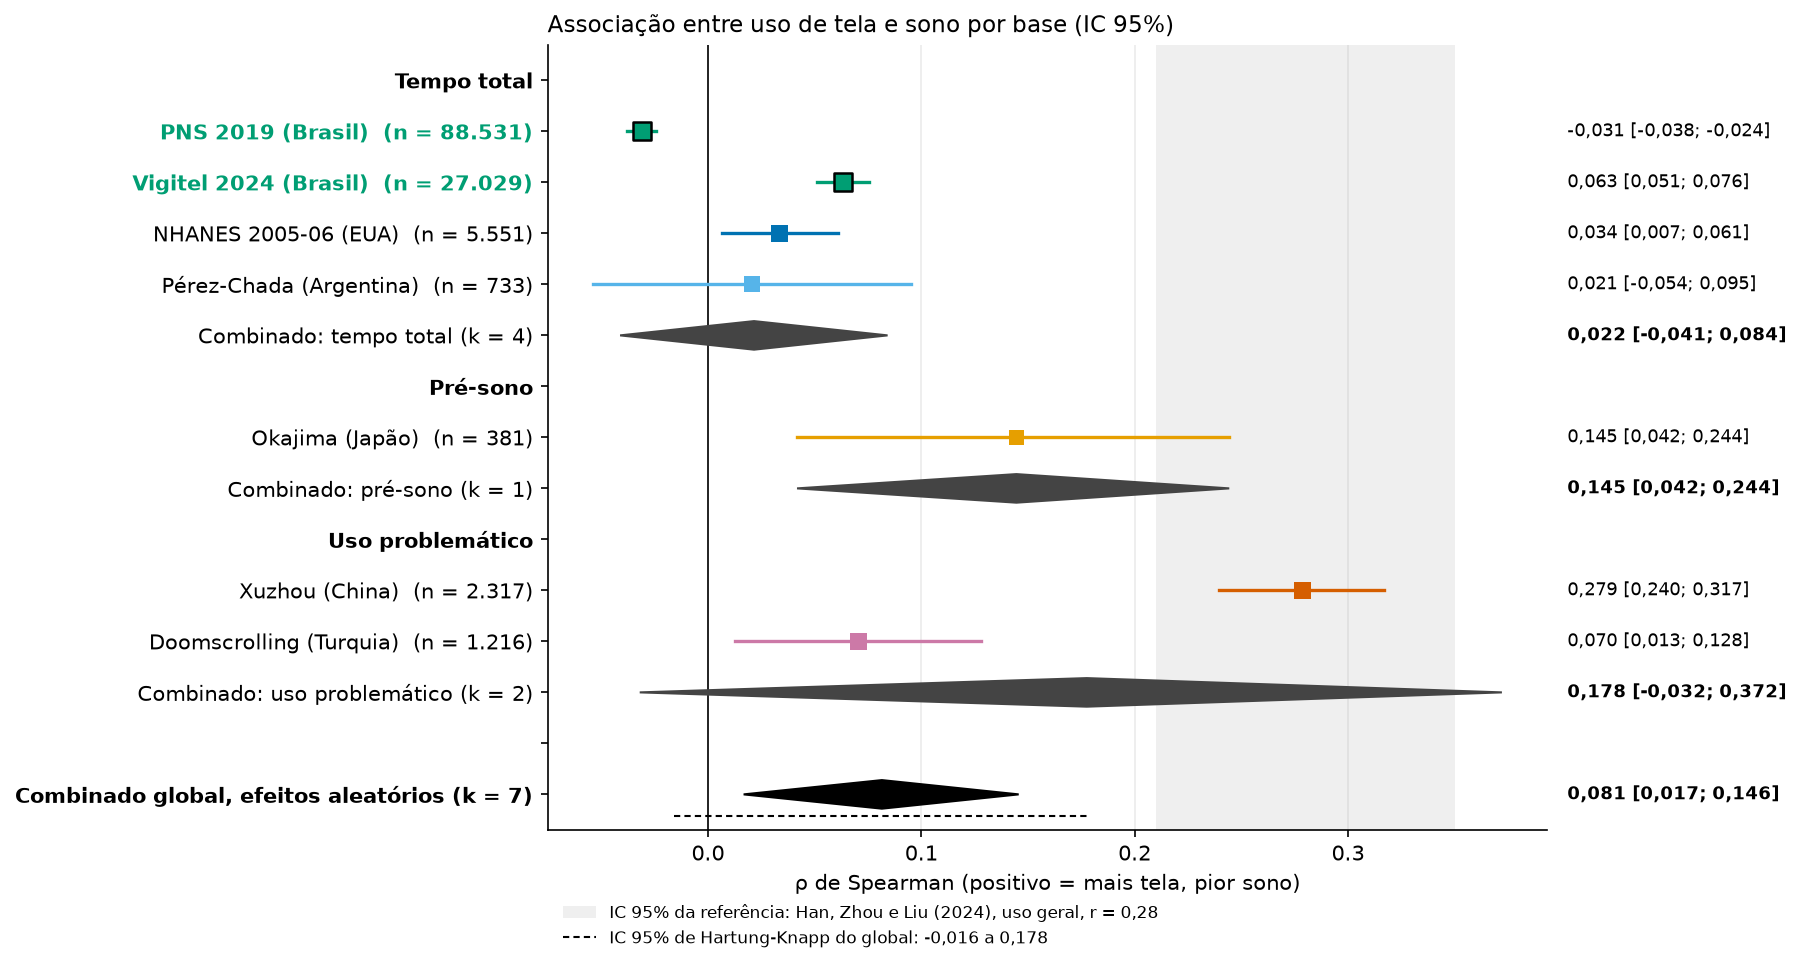

In [12]:
display(Image(filename=str(FIG / "floresta.png")))

## 6. Sensibilidades

- **Bruta × ajustada por idade** (princípio 11): ρ parcial de Spearman controlando a idade. Na PNS o sinal muda: o ρ bruto negativo reflete confundimento por idade (jovens usam mais tela e relatam menos problema de sono), o mesmo padrão da exploração de 27/11 (RP bruta 0,90 → ajustada 1,17).
- Deixar uma base de fora; ρ ponderado pelo peso amostral nos inquéritos; pares alternativos; bases de procedência questionável (só aqui, rotuladas); contraponto intrapessoal da Holanda.

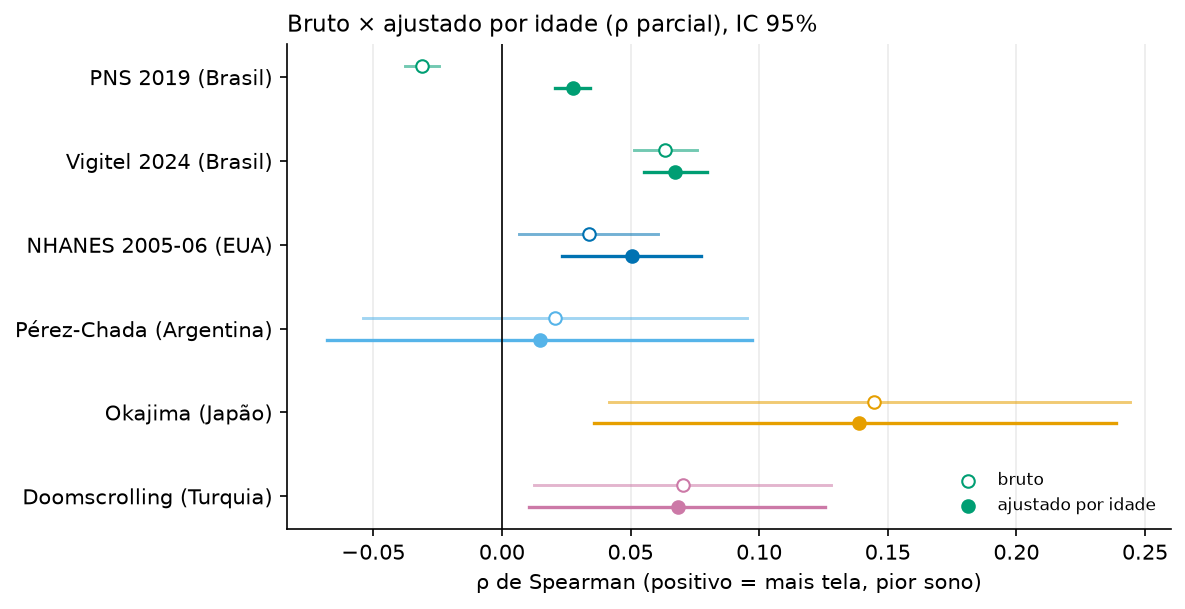

,base,nome,pais,tipo,rho_bruto,ic_inf_bruto,ic_sup_bruto,n_bruto,rho_ajustado_idade,ic_inf_ajustado,ic_sup_ajustado,n_ajustado
0,pns2019,PNS 2019 (Brasil),Brasil,tempo total,-0.031,-0.038,-0.024,88531,0.027,0.021,0.034,88531
1,vigitel2024,Vigitel 2024 (Brasil),Brasil,tempo total,0.063,0.051,0.076,27029,0.067,0.055,0.080,27029
2,nhanes0506,NHANES 2005-06 (EUA),EUA,tempo total,0.034,0.007,0.061,5551,0.051,0.023,0.078,5551
3,argentina,Pérez-Chada (Argentina),Argentina,tempo total,0.021,-0.054,0.095,733,0.015,-0.068,0.097,598
4,japao,Okajima (Japão),Japão,pré-sono,0.145,0.042,0.244,381,0.139,0.036,0.239,381
5,turquia,Doomscrolling (Turquia),Turquia,uso problemático,0.070,0.013,0.128,1216,0.068,0.010,0.126,1216


In [13]:
display(Image(filename=str(FIG / "bruta_ajustada_idade.png")))
le_csv(TAB / "bruta_ajustada_idade.csv").round(3)

In [14]:
le_csv(TAB / "sensibilidade.csv")[["grupo", "analise", "k", "n", "rho", "ic_inf", "ic_sup", "I2"]].round(3)

,grupo,analise,k,n,rho,ic_inf,ic_sup,I2
0,deixar uma de fora,sem PNS 2019 (Brasil),6,NaN,0.102,0.032,0.172,0.956
1,deixar uma de fora,sem Vigitel 2024 (Brasil),6,NaN,0.086,-0.011,0.181,0.980
2,deixar uma de fora,sem NHANES 2005-06 (EUA),6,NaN,0.090,0.015,0.165,0.987
3,deixar uma de fora,sem Pérez-Chada (Argentina),6,NaN,0.091,0.021,0.160,0.987
4,deixar uma de fora,sem Okajima (Japão),6,NaN,0.073,0.005,0.141,0.987
5,deixar uma de fora,sem Xuzhou (China),6,NaN,0.044,-0.010,0.097,0.975
6,deixar uma de fora,sem Doomscrolling (Turquia),6,NaN,0.083,0.013,0.153,0.987
7,ponderada,PNS 2019 (Brasil): ρ ponderado pelo peso amostral,1,88531.0,-0.041,NaN,NaN,NaN
8,ponderada,Vigitel 2024 (Brasil): ρ ponderado pelo peso amostral,1,27029.0,0.069,NaN,NaN,NaN
9,ponderada,NHANES 2005-06 (EUA): ρ ponderado pelo peso amostral,1,5551.0,0.015,NaN,NaN,NaN


## 7. O que isto permite dizer (e o que não permite)

- A associação entre tela e sono é **pequena e positiva** na maior parte das bases, mas **varia muito entre elas** (H4.1). A estimativa combinada global resume bases heterogêneas e deve ser lida com cuidado.
- Com só 1 a 4 bases por subgrupo, o Q entre subgrupos tem pouco poder: "não rejeitar H0" em H4.2 **não** mostra que os tipos de exposição têm o mesmo efeito.
- Não foi detectada diferença entre o Brasil e os outros países com tempo total (H4.3; a diferença na escala z tem IC de −0,11 a 0,08, compatível com diferenças pequenas nos dois sentidos), mas as duas bases brasileiras discordam entre si: PNS bruta negativa, Vigitel positiva. Ajustadas por idade, ambas ficam positivas.
- As nossas reanálises de tempo total ficam **abaixo** do intervalo da meta-análise de referência (H4.4). A referência mede uso geral × qualidade do sono, majoritariamente em jovens; nossos desfechos são insônia, problema de sono e latência em populações gerais. A diferença pode ser de população, de medida ou de seleção de estudos publicados.
- São dados transversais: o resultado é associação, não mostra causa.